# GastroLens — Module 1: Autoencoder
Synthetic GI endoscopy image generation using a convolutional Autoencoder, trained on the Kvasir-v2 dataset.

This notebook:
- Loads Kvasir-v2 images (folder-per-class structure)
- Trains a convolutional Autoencoder for image reconstruction/generation
- Saves the trained model (skips retraining if a checkpoint already exists, unless `FORCE_RETRAIN=True`)
- Logs per-epoch loss to CSV and plots the training curve
- Computes evaluation metrics (MSE, PSNR, SSIM, FID) on held-out samples
- Saves everything under `models/autoencoder/`, `metrics/autoencoder/`, `plots/autoencoder/`

## 1. Config

In [1]:
import os

# ---- Paths ----
DATA_DIR = "./data/kvasir-v2"          # expects subfolders per class, e.g. data/kvasir-v2/polyps/*.jpg
MODEL_DIR = "./models/autoencoder"
METRICS_DIR = "./metrics/autoencoder"
PLOTS_DIR = "./plots/autoencoder"

for d in [MODEL_DIR, METRICS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

CHECKPOINT_PATH = os.path.join(MODEL_DIR, "autoencoder_best.pth")
LOSS_LOG_PATH = os.path.join(METRICS_DIR, "training_loss_log.csv")
METRICS_PATH = os.path.join(METRICS_DIR, "evaluation_metrics.json")
LOSS_PLOT_PATH = os.path.join(PLOTS_DIR, "loss_curve.png")
SAMPLES_PLOT_PATH = os.path.join(PLOTS_DIR, "reconstruction_samples.png")

# ---- Hyperparameters ----
IMG_SIZE = 128
BATCH_SIZE = 64
LATENT_DIM = 128
EPOCHS = 100
LEARNING_RATE = 1e-3
VAL_SPLIT = 0.1
SEED = 42

# Set True to retrain even if a checkpoint already exists
FORCE_RETRAIN = False

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
DATA_DIR = "./data_dir"

## 2. Dataset

In [5]:
# Kvasir-v2 is organized as data_dir/<class_name>/<image>.jpg — ImageFolder handles this directly.
# Labels aren't used for training the Autoencoder itself (it's unsupervised reconstruction),
# but keeping them around lets you later break down reconstruction quality per class if you want to.

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),               # scales to [0, 1]
])

full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=transform)
class_names = full_dataset.classes
print(f"Found {len(full_dataset)} images across {len(class_names)} classes: {class_names}")

val_size = int(len(full_dataset) * VAL_SPLIT)
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Found 8000 images across 8 classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']
Train: 7200 | Val: 800


## 3. Model — Convolutional Autoencoder
Mirrors the encoder/decoder shape used for the VAE (3→32→64→128 conv layers), minus the probabilistic bottleneck — this keeps your three architectures directly comparable, same as the reference paper's approach.

In [6]:
class Encoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),   # 128 -> 64
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 64 -> 32
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 32 -> 16
            nn.ReLU(inplace=True),
        )
        self.fc = nn.Linear(128 * 16 * 16, latent_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class Decoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128 * 16 * 16)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 16 -> 32
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # 32 -> 64
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),    # 64 -> 128
            nn.Sigmoid(),   # output in [0, 1] to match ToTensor() scaling
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(x.size(0), 128, 16, 16)
        return self.deconv(x)


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


model = Autoencoder(LATENT_DIM).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Autoencoder parameters: {n_params:,}")

Autoencoder parameters: 8,752,579


## 4. Train (skips automatically if a checkpoint already exists)

In [7]:
def evaluate_val_loss(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(device)
            recon = model(imgs)
            loss = criterion(recon, imgs)
            total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


def train_autoencoder():
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"epoch": [], "train_loss": [], "val_loss": [], "epoch_time_sec": []}
    best_val_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        start = time.time()
        running_loss = 0.0

        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            optimizer.zero_grad()
            recon = model(imgs)
            loss = criterion(recon, imgs)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)

        train_loss = running_loss / len(train_dataset)
        val_loss = evaluate_val_loss(model, val_loader, criterion)
        epoch_time = time.time() - start

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time_sec"].append(epoch_time)

        print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.5f} | val_loss={val_loss:.5f} | {epoch_time:.1f}s")

        # Save best checkpoint
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "latent_dim": LATENT_DIM,
                "img_size": IMG_SIZE,
            }, CHECKPOINT_PATH)

        # Save loss log every epoch so progress isn't lost if training is interrupted
        pd.DataFrame(history).to_csv(LOSS_LOG_PATH, index=False)

    return history


if os.path.exists(CHECKPOINT_PATH) and not FORCE_RETRAIN:
    print(f"Checkpoint found at {CHECKPOINT_PATH} — loading instead of retraining.")
    print("Set FORCE_RETRAIN = True above to retrain from scratch.")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.5f})")
    if os.path.exists(LOSS_LOG_PATH):
        history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list")
    else:
        history = None
else:
    print("Training Autoencoder from scratch...")
    history = train_autoencoder()
    # reload best checkpoint after training completes
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded best checkpoint (epoch {checkpoint['epoch']}, val_loss={checkpoint['val_loss']:.5f})")

Checkpoint found at ./models/autoencoder\autoencoder_best.pth — loading instead of retraining.
Set FORCE_RETRAIN = True above to retrain from scratch.
Loaded model from epoch 27 (val_loss=0.00246)


In [ ]:
# ---- Load the already-trained Autoencoder checkpoint (no training) ----
model = Autoencoder(LATENT_DIM).to(device)   # skip this line if `model` already exists in this session

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.5f})")

# Load the loss history too, if you want the training curve without retraining
history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list") if os.path.exists(LOSS_LOG_PATH) else None

## 5. Plot training curve

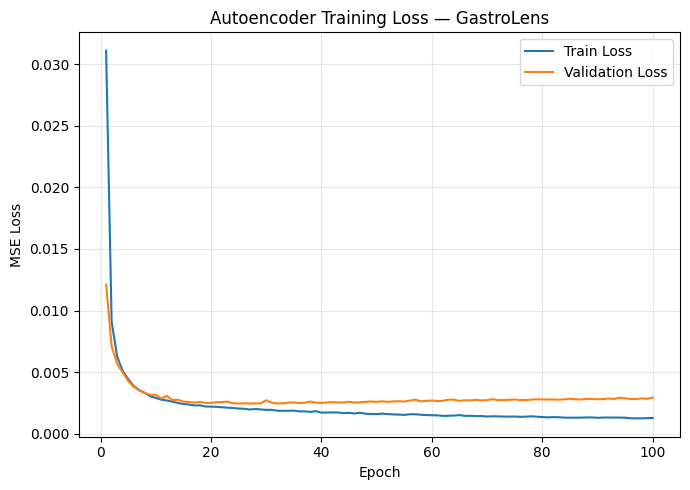

Saved loss curve to ./plots/autoencoder\loss_curve.png


In [8]:
if history is not None:
    plt.figure(figsize=(7, 5))
    plt.plot(history["epoch"], history["train_loss"], label="Train Loss")
    plt.plot(history["epoch"], history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Autoencoder Training Loss — GastroLens")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(LOSS_PLOT_PATH, dpi=150)
    plt.show()
    print(f"Saved loss curve to {LOSS_PLOT_PATH}")
else:
    print("No loss history available (loaded a checkpoint with no matching log file).")

## 6. Evaluation metrics
MSE, PSNR, SSIM computed on the validation set; FID computed between real validation images and their reconstructions (same evaluation style as the reference paper).

In [9]:
# pip install scikit-image pytorch-fid --break-system-packages   (run in a terminal cell if not already installed)
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn


def compute_reconstruction_metrics(model, loader, max_batches=None):
    model.eval()
    mse_list, psnr_list, ssim_list = [], [], []

    with torch.no_grad():
        for i, (imgs, _) in enumerate(loader):
            if max_batches is not None and i >= max_batches:
                break
            imgs = imgs.to(device)
            recon = model(imgs)

            imgs_np = imgs.cpu().numpy()
            recon_np = recon.cpu().numpy()

            for orig, rec in zip(imgs_np, recon_np):
                orig_hwc = np.transpose(orig, (1, 2, 0))
                rec_hwc = np.transpose(rec, (1, 2, 0))

                mse_list.append(np.mean((orig_hwc - rec_hwc) ** 2))
                psnr_list.append(psnr_fn(orig_hwc, rec_hwc, data_range=1.0))
                ssim_list.append(ssim_fn(orig_hwc, rec_hwc, data_range=1.0, channel_axis=2))

    return {
        "MSE": float(np.mean(mse_list)),
        "PSNR": float(np.mean(psnr_list)),
        "SSIM": float(np.mean(ssim_list)),
    }


recon_metrics = compute_reconstruction_metrics(model, val_loader)
print("Reconstruction metrics (validation set):")
for k, v in recon_metrics.items():
    print(f"  {k}: {v:.4f}")

Reconstruction metrics (validation set):
  MSE: 0.0025
  PSNR: 26.9482
  SSIM: 0.7281


In [10]:
# FID between real and reconstructed images — saved to disk as image folders, then scored with pytorch-fid.
# This mirrors how the reference paper evaluates synthetic quality.
import shutil
from torchvision.utils import save_image

FID_REAL_DIR = os.path.join(METRICS_DIR, "fid_real")
FID_FAKE_DIR = os.path.join(METRICS_DIR, "fid_fake")
for d in [FID_REAL_DIR, FID_FAKE_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)

model.eval()
idx = 0
with torch.no_grad():
    for imgs, _ in val_loader:
        imgs = imgs.to(device)
        recon = model(imgs)
        for orig, rec in zip(imgs, recon):
            save_image(orig, os.path.join(FID_REAL_DIR, f"{idx}.png"))
            save_image(rec, os.path.join(FID_FAKE_DIR, f"{idx}.png"))
            idx += 1

print(f"Saved {idx} real/reconstructed pairs for FID scoring.")
print("Run: python -m pytorch_fid", FID_REAL_DIR, FID_FAKE_DIR)

# Uncomment to compute FID directly from this notebook (requires: pip install pytorch-fid --break-system-packages)
# from pytorch_fid.fid_score import calculate_fid_given_paths
# fid_score = calculate_fid_given_paths([FID_REAL_DIR, FID_FAKE_DIR], batch_size=50, device=device, dims=2048)
# recon_metrics["FID"] = float(fid_score)
# print(f"FID: {fid_score:.2f}")

Saved 800 real/reconstructed pairs for FID scoring.
Run: python -m pytorch_fid ./metrics/autoencoder\fid_real ./metrics/autoencoder\fid_fake


In [11]:
# Save all metrics to JSON so later notebooks (VAE, GAN, Transformer, Diffusion) can
# load this same file structure and build one combined comparison table.
with open(METRICS_PATH, "w") as f:
    json.dump(recon_metrics, f, indent=2)

print(f"Saved metrics to {METRICS_PATH}")
print(json.dumps(recon_metrics, indent=2))

Saved metrics to ./metrics/autoencoder\evaluation_metrics.json
{
  "MSE": 0.002456849440932274,
  "PSNR": 26.94821368593707,
  "SSIM": 0.7280557155609131
}


## 7. Visualize sample reconstructions

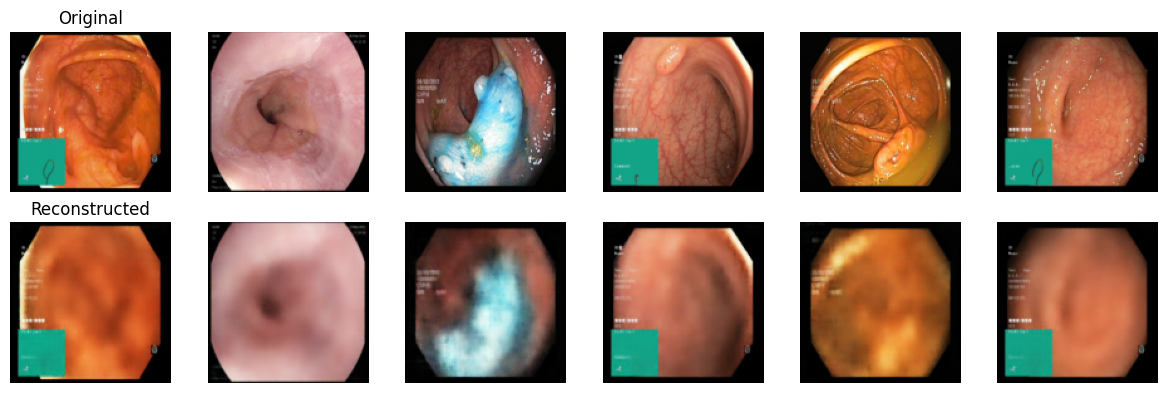

Saved sample grid to ./plots/autoencoder\reconstruction_samples.png


In [12]:
model.eval()
imgs, _ = next(iter(val_loader))
imgs = imgs.to(device)
with torch.no_grad():
    recon = model(imgs)

n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4))
for i in range(n_show):
    axes[0, i].imshow(imgs[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].axis("off")
    axes[0, i].set_title("Original" if i == 0 else "")

    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy())
    axes[1, i].axis("off")
    axes[1, i].set_title("Reconstructed" if i == 0 else "")

plt.tight_layout()
plt.savefig(SAMPLES_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved sample grid to {SAMPLES_PLOT_PATH}")

d:\Savita\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Savita\.venv\lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loaded pretrained Stable Diffusion VAE (reference model, not trained by us).


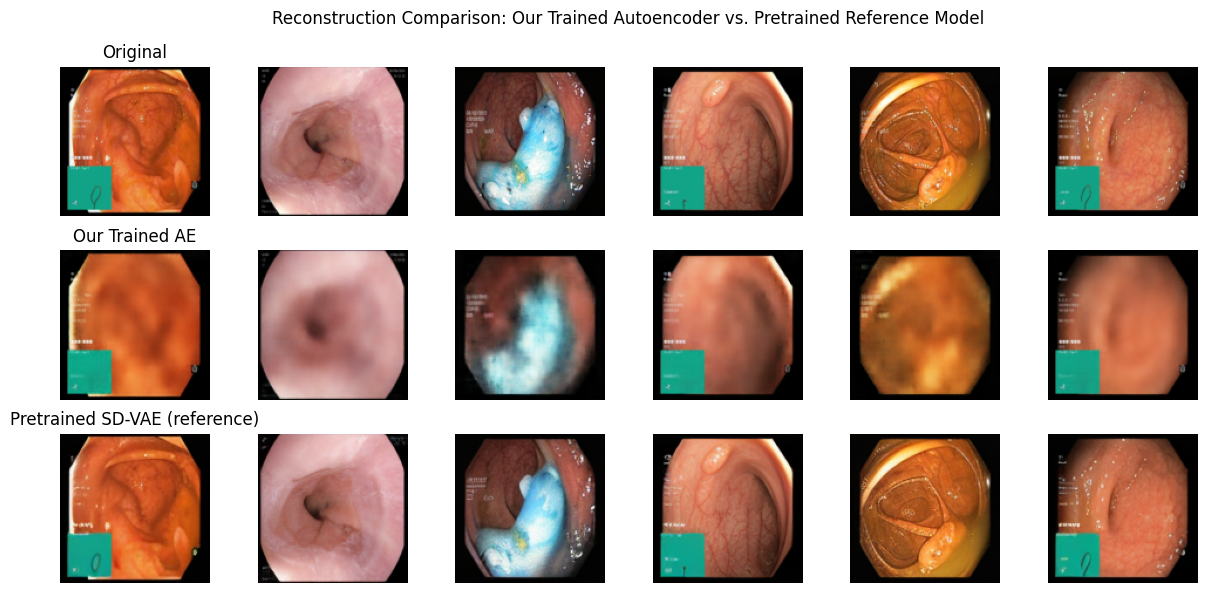

Saved comparison to ./plots/autoencoder\pretrained_vae_comparison.png


In [13]:
# ---- Pretrained Reference Model: Stable Diffusion VAE ----
# pip install diffusers transformers accelerate

from diffusers import AutoencoderKL
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import os

# Load the pretrained VAE (downloads once, then cached locally)
pretrained_vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)
pretrained_vae.eval()
for p in pretrained_vae.parameters():
    p.requires_grad = False

print("Loaded pretrained Stable Diffusion VAE (reference model, not trained by us).")


def reconstruct_with_pretrained_vae(img_tensor):
    """
    img_tensor: (C, H, W) in [0, 1] range, single image (no batch dim)
    Stable Diffusion's VAE expects input normalized to [-1, 1], and
    outputs latents scaled by a fixed constant (0.18215) — both handled here.
    """
    img_batch = img_tensor.unsqueeze(0).to(device)
    img_scaled = img_batch * 2.0 - 1.0  # [0,1] -> [-1,1]

    with torch.no_grad():
        latent = pretrained_vae.encode(img_scaled).latent_dist.sample()
        latent = latent * 0.18215
        recon = pretrained_vae.decode(latent / 0.18215).sample

    recon = (recon.clamp(-1, 1) + 1.0) / 2.0  # [-1,1] -> [0,1]
    return recon.squeeze(0).cpu()


# ---- Run on the same batch used for your own model, for a fair side-by-side ----
n_show = 6
fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))

for i in range(n_show):
    original = imgs[i].cpu()
    our_recon = recon[i].cpu()                                  # from your trained Autoencoder
    pretrained_recon = reconstruct_with_pretrained_vae(imgs[i])  # from pretrained SD VAE

    axes[0, i].imshow(original.permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("Original" if i == 0 else "")

    axes[1, i].imshow(our_recon.permute(1, 2, 0).numpy()); axes[1, i].axis("off")
    axes[1, i].set_title("Our Trained AE" if i == 0 else "")

    axes[2, i].imshow(pretrained_recon.permute(1, 2, 0).numpy()); axes[2, i].axis("off")
    axes[2, i].set_title("Pretrained SD-VAE (reference)" if i == 0 else "")

plt.suptitle("Reconstruction Comparison: Our Trained Autoencoder vs. Pretrained Reference Model")
plt.tight_layout()

PRETRAINED_COMPARISON_PATH = os.path.join(PLOTS_DIR, "pretrained_vae_comparison.png")
plt.savefig(PRETRAINED_COMPARISON_PATH, dpi=150)
plt.show()
print(f"Saved comparison to {PRETRAINED_COMPARISON_PATH}")

In [14]:
# Save the pretrained reference model locally so future runs don't need internet access
PRETRAINED_SAVE_DIR = os.path.join(MODEL_DIR, "pretrained_reference")
os.makedirs(PRETRAINED_SAVE_DIR, exist_ok=True)

pretrained_vae.save_pretrained(PRETRAINED_SAVE_DIR)
print(f"Saved pretrained reference model to {PRETRAINED_SAVE_DIR}")

Saved pretrained reference model to ./models/autoencoder\pretrained_reference


In [15]:
pretrained_vae = AutoencoderKL.from_pretrained(PRETRAINED_SAVE_DIR).to(device)

In [16]:
PRETRAINED_OUTPUTS_DIR = os.path.join(MODEL_DIR, "pretrained_reference_outputs")
os.makedirs(PRETRAINED_OUTPUTS_DIR, exist_ok=True)

for i in range(n_show):
    pretrained_recon = reconstruct_with_pretrained_vae(imgs[i])
    save_image(pretrained_recon, os.path.join(PRETRAINED_OUTPUTS_DIR, f"pretrained_recon_{i}.png"))

print(f"Saved {n_show} pretrained reference reconstructions to {PRETRAINED_OUTPUTS_DIR}")

Saved 6 pretrained reference reconstructions to ./models/autoencoder\pretrained_reference_outputs


## Output summary

| Artifact | Path |
|---|---|
| Trained model checkpoint | `models/autoencoder/autoencoder_best.pth` |
| Per-epoch loss log (CSV) | `metrics/autoencoder/training_loss_log.csv` |
| Evaluation metrics (MSE, PSNR, SSIM) | `metrics/autoencoder/evaluation_metrics.json` |
| Real/reconstructed image pairs for FID | `metrics/autoencoder/fid_real/`, `metrics/autoencoder/fid_fake/` |
| Loss curve plot | `plots/autoencoder/loss_curve.png` |
| Sample reconstructions plot | `plots/autoencoder/reconstruction_samples.png` |

Next: repeat this same folder structure (`models/vae/`, `metrics/vae/`, `plots/vae/`, etc.) for VAE, GAN, Transformer, and Diffusion so all five slot into one shared comparison table at the end.